# Reinforcement learning and pre-training

Over the past week or so we've been talking about the basic structure of machine learning algorithms. In many ways, they are just "fancier" versions of the modeling techniques we covered in previous units. My plan for this notebook it to introduce some if the ideas and techniques that sit behind modern large language models (LLM) that power chat bots and coding agents, like the ones involved in the Hugging Face incident.

We saw in the last notebook that the data used has a **huge** impact on the model and its validity. This is in someway the old computer science addage "garbage in, garbage out." If your training data is the *entire* internet and every book or paper ever written (a lot of that is just kinda garbage) this begs a question: How can you take that mess of data and build a model than can solve previously unsolved [research-level math problems](https://www.bbc.com/news/articles/cy7zygy3rl2o)? 

The answer (or at least parts of it) live in **Pre-training** and **Reinforcement learning.** 

When we say *pre-training* we mean doing a fully automated task to try to learn something about the data. In the example of an LLM, that might be just trying to predict the next word given the previous text in a document. In order to get good at this skill of prediction, you need to learn something about how language is constructed. It also does not need a human or well-curated dataset. It can predict the next word in a tweet just as easily as the next word in a Tolstoy novel. 

The name *reinforcement learning* comes from psychology. It's how we, as mammals, learn. The basic ideas is that when the model does something *good* we give it a virtual award (some points). When a model does something *bad* we give it a punishment by removing points. We then give a model a bunch of tasks, and score the outcome, incentivising the model to get as high a score as possible. 

Many of the recent gains in the performance of LLMs have been do in reinforcement learning, and it is part of the reason why these models are so good at math and coding. Because math and coding problems often have *verifiable answers* (it's easy to say if the answer is correct or not) you can run a reinformed learning loop on these sorts of problems easily. Other problems, like the answer to a chatbot message are squishier. This is part of the issue with sycophancy in chatbots, if part of the training is RL on human input, and humans liked to be told they are good and smart, is it really a surprise we see these chatbots behaving like they have? 

### Setting up the code 

I've decided to hide most of the code from you, and only expose a few functions. The entirety of the code can be found [here](), most of it was written by one of those coding agents I mentioned above. I have also trained a few different version of our test model the same way the authors of that New York Times piece did in the interest of time.  

Run the cell below to import all of the python packages we will use in this notebook, including the custom maze code.

In [1]:
# Install the maze code (takes about a minute)
#%pip install -q git+https://github.com/anthoak13/HNR-MazeSolver@maze-rl

%pip install -q --force-reinstall --no-deps git+https://github.com/anthoak13/HNR-MazeSolver@maze-rl
# Import the maze code and other libraries used in this notebook
import mazerl as mz
import pandas as pd
from IPython.display import display


Note: you may need to restart the kernel to use updated packages.


Run the cell below to make sure the code loaded correctly. You should see the images one of the mazes from the NYTimes article when you do.

In [2]:
# Maze where the flag is behind a weak spot in the wall"
display(mz.show_maze(mz.scenario("enclosed")))


## Defining the model

Our testbed for this exploration will be a maze-solving agent. In this model, there are 14X14 mazes sitting in a 18X18 world. Each maze has a flag sitting somewhere in the middle. The agent is a dot who can walk around the maze to try to find the flag. Some of the walls are "vulnerable" and if the agent probes them, can discover a hidden passageway through the maze. As you can see above, I have visualized these will a light gray square.

Our eventual goal is to train an agent who can solve any random maze given to them, even a very hard one like this "enclosed" example. The code cell below will pull a working version of the model I trained based on the (limited) information for the Times authors. It then runs on the maze above. You can have it solve a random maze by changing which line of code is uncommented.

In [3]:
# The full-scale agent with the default rewards
base = mz.load_pretrained("base")

maze = mz.scenario("enclosed")
maze = mz.random_mazes(1)[0]

mz.playback(base, maze=maze, n_agents=5, seed=0)



We're going to take this in four parts:
1. Defining the data and behavior for the agent
2. Pre-training the agent to learn about mazes
3. Training the agent to solve mazes using RL (and see how they can learn to solve mazes not in their training data)
4. Examining how changes in rewards/punishments can effect the behavior of our agents

## Part 1: Defining an agent

For our agent to be an effective maze solver, it will need some skills (but not too many, it wouldn't be much of a challange if our agent could see the intire maze now would it!).

**What skills or information (i.e., data) would you give the agent if you were building it from scratch?**

- 
- 

----

### What an agent sees

For agent to have any hope of success, we will need to give it three things. A memory about the size of the maze, some basic vision, and a vague sense for what direction the flag might be in. In this model the agent has:
1. An 11X11 sized memory centered on itself. 
2. The ability to see up to two squares away, but its vision is blocked by solid walls. 
3. A memory of where the agent has been before
4. A memory of what walls the agent has prodded before
5. A single number (1-8) that indicates in what direction the flag is in

For the memory, there 9 things which could be true we need to track:
- not seen
- open floor
- outside
- wall
- flag
- map edge
- can see now
- have prodded
- have stood

For each cell, these can either be true (1) or false (0) so what we do is just store nine $11\times 11$ lists where each cell is either a 1 or a 0 depending on the agent's knowledge. The direction has eight options so we pass eight numbers (all zero but the correct direction which i 1), so in the end we are passing $9\times 11\times 11 +8 = 1097$ numbers to the model (or 1097).

If you run the cell below, it will show what an agent would see. You can play around with different examples by changing the step (larger number means the agent has wandered for longer) and seed (a different "trial"). 

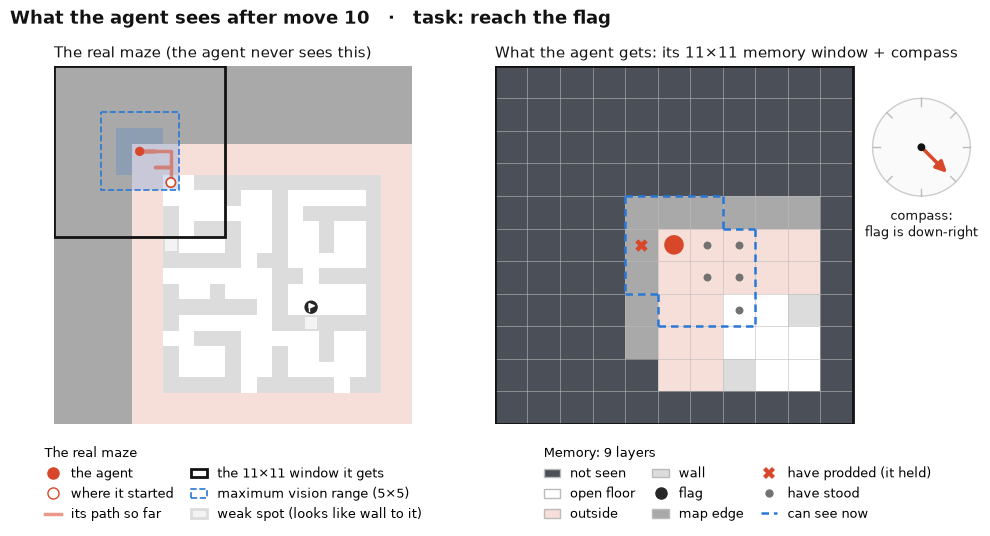

In [4]:
# One new maze, used throughout Part 1
maze = mz.random_mazes(1)[0]

mz.show_observation(maze=maze, step=10, seed=0)


### How an agent behaves

The behavior of our agent will be determined by the **output** of our model. When we were identifying digits, the output of our model was 10 numbers all 0-1. We said the digit the model identified was whichever was largest. We will do something here where the output of our model will be 4 numbers that correspond to moving: up, down, right, and left. Technically, there is a fifth output but that is just used for training. It is sort of like the model's "confidence" in its ability to solve the maze.

Unlike the digits, where we always picked the most likely outcome, when we are using the model we will treat the outputs as a probability. For example, if the output was `[0.5, 0.5 , 0, 1]` we would interpret that as a 25\% chance of going up,  a 25\% chance of going down, and a 50\% chance of going left.

Once the agent moves, we can update our memory and pass it all back to the model to generate a new prediction for our next move. And then repeat until we reach the flag (hopefully)

You can see this in the example below where each of the five agents (all using the same model) take different paths. Some take the 25\% chance and some take the 50\% chance.

In [5]:
base = mz.load_pretrained("base")
maze = mz.scenario("enclosed")
mz.playback(base, maze=maze, n_agents=5, seed=0)

### How an agent thinks

Now that we have defined the input and output, we can discuss what the "brains," or network architecture looks like. I made a best guess for what this would have been in the NYTimes article based on the limited information. The ML network has two halves:

The first half is a "vision" or "perception" half. It's responsible for taking in all our memory (as well as the eight compass numbers) and distilling it into 100 "features" which describe the world around the agent. 

The second half takes as its input the 100 "features" from the vision section and makes a prediction. This is the "reasoning" part. It has one more fully connected layer before the output. This is like the last hidden layer on our character finder, but now the hidden layers are 100 neurons rather than 16. The final output layer is 4 numbers, referring to the four directions.

## Part 2: (Pre)-training an agent

In principle, there are a bunch of different tasks we could do with a maze-based agent. It could search for a flag or it could try to break out of a maze. Both of these need different strategies, but they share a lot of common knowledge. An agent needs to learn about walls, and vulnerable sections of wall, and how rooms are constructed, etc.

Just like in LLMs, we can "pre-train" a model by having it ingest the entire internet and having it guess the nest token, we can do something similar for our maze model. For a task to be a good pre-training task it should not need any human input. In out case, we will have the agent **predict** what each square in its memory is, that is has not seen yet. In order to be good at this task, you need to understand something about how mazes are constructed which should be useful in solving all sorts of maze-based task!

### The data

In order to get an agent to predict what is within the "fog of war" in its memory, we will need some basic agent that can walk around a maze. This is something we can do easily with ML. I wrote a little script that has the agent walk towards the nearest empty square it hasn't seen before (most of the time, there is a 30\% change it just moves randomly). We let an agent take 100 steps in each of the 13,184 training mazes. After each step we save a snapshot of the current memory of the agent (the nine $11\times 11$ maps discussed above). We also save the "true" state of each cell in the memory block, even if the agent hasn't seen it yet.

Critically, everything we just described was with NO ML. All we have done is automatically generated a dataset to use for pretraining. The cell below shows the path the explorer might have taken of a random maze.




In [9]:
# The scripted explorer wandering one maze
maze = mz.random_mazes(1)[0]
mz.playback("explorer", maze=maze, n_agents=1)

### The task

For each "snapshot" we took, we ask the model to answer the question **for each square it hasn't seen yet, what's really
there?** 1) Open floor, 2) outside, 3) wall, or 4) the edge of the map. Mechanically, this means we are taking the 100 "features" from the vision model and generating 4 output numbers for each of the 121 cells. This is exactly the same as our character recognition, except we have 4 answers (instead of 10) and we are doing it once for each cell, rather than once for the whole image.

**If the model were randomly guessing (or always guessing the most common answer), how often would it get the hidden cells correct?**

Let's take a look at how the model does before and after this round of pre-training. If you run the cell below, it will generate two images showing the guesses of the model before and after pre-training. 

In [ ]:
# Load the network that was pretrained this way (no rewards involved)
perception = mz.load_perception("perception")

# How well it does on mazes it never saw during pretraining
t = perception.test
print(f"Hidden squares guessed right: {t['map_acc_unseen']:.0%}"
      f"   (always guessing the most common kind: {t['map_acc_majority_baseline']:.0%})")

Hidden squares guessed right: 86%   (always guessing the most common kind: 53%)


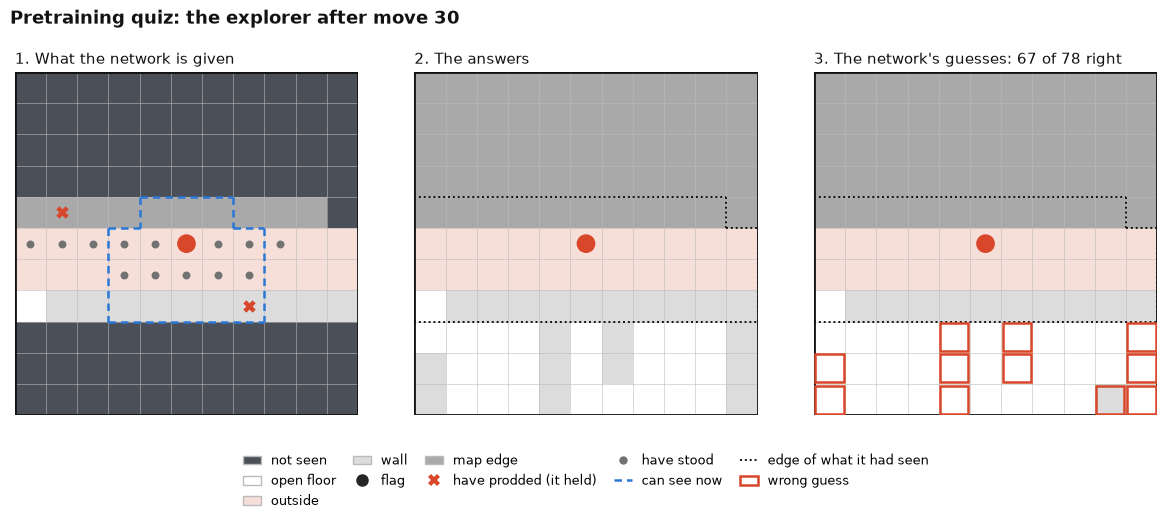

In [11]:
mz.show_pretraining_quiz(perception, maze=maze, step=30, seed=0)